In [1]:
# Cell 1: Installation
!pip install -q captum

Using device: cuda

Starting Automated OCR Extraction...
Found existing preprocessed CSV: /kaggle/working/Train_processed.csv
Found existing preprocessed CSV: /kaggle/working/Validation_processed.csv
Found existing preprocessed CSV: /kaggle/working/Test_processed.csv
📄 Loaded CSV: Train_processed.csv | 🖼️ Found Images: 2399 / 2400
📄 Loaded CSV: Validation_processed.csv | 🖼️ Found Images: 300 / 300
📄 Loaded CSV: Test_processed.csv | 🖼️ Found Images: 300 / 300


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense.bias              | UNEXPECTED |  | 
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/423 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-base-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Evaluation Phase Starting...
✅ Best saved Intermediate Fusion Model Loaded Successfully!


Testing: 100%|██████████| 38/38 [00:14<00:00,  2.64it/s]



TEST RESULT
Test Accuracy : 0.9833
Test Precision: 0.9835
Test Recall   : 0.9833
Test F1 Score : 0.9833


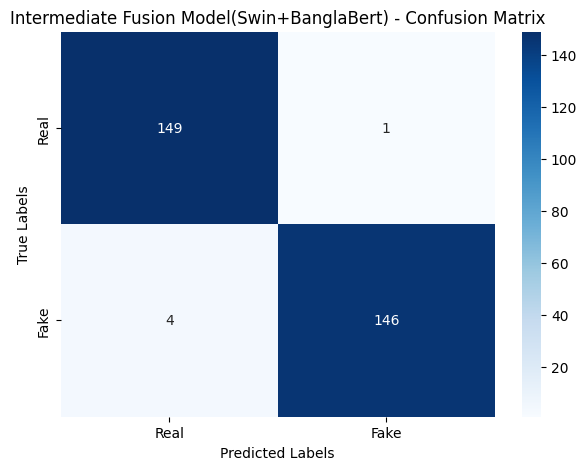

/tmp/ipykernel_910/3406282253.py:672: UserWarning: Glyph 2488 (\N{BENGALI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_910/3406282253.py:672: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_910/3406282253.py:672: UserWarning: Glyph 2503 (\N{BENGALI VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_910/3406282253.py:672: UserWarning: Glyph 2474 (\N{BENGALI LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_910/3406282253.py:672: UserWarning: Glyph 2509 (\N{BENGALI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_910/3406282253.py:672: UserWarning: Glyph 2463 (\N{BENGALI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_910/3406282253.py:672: UserWarning: Glyph 2478 (\N{BENGALI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_910/3

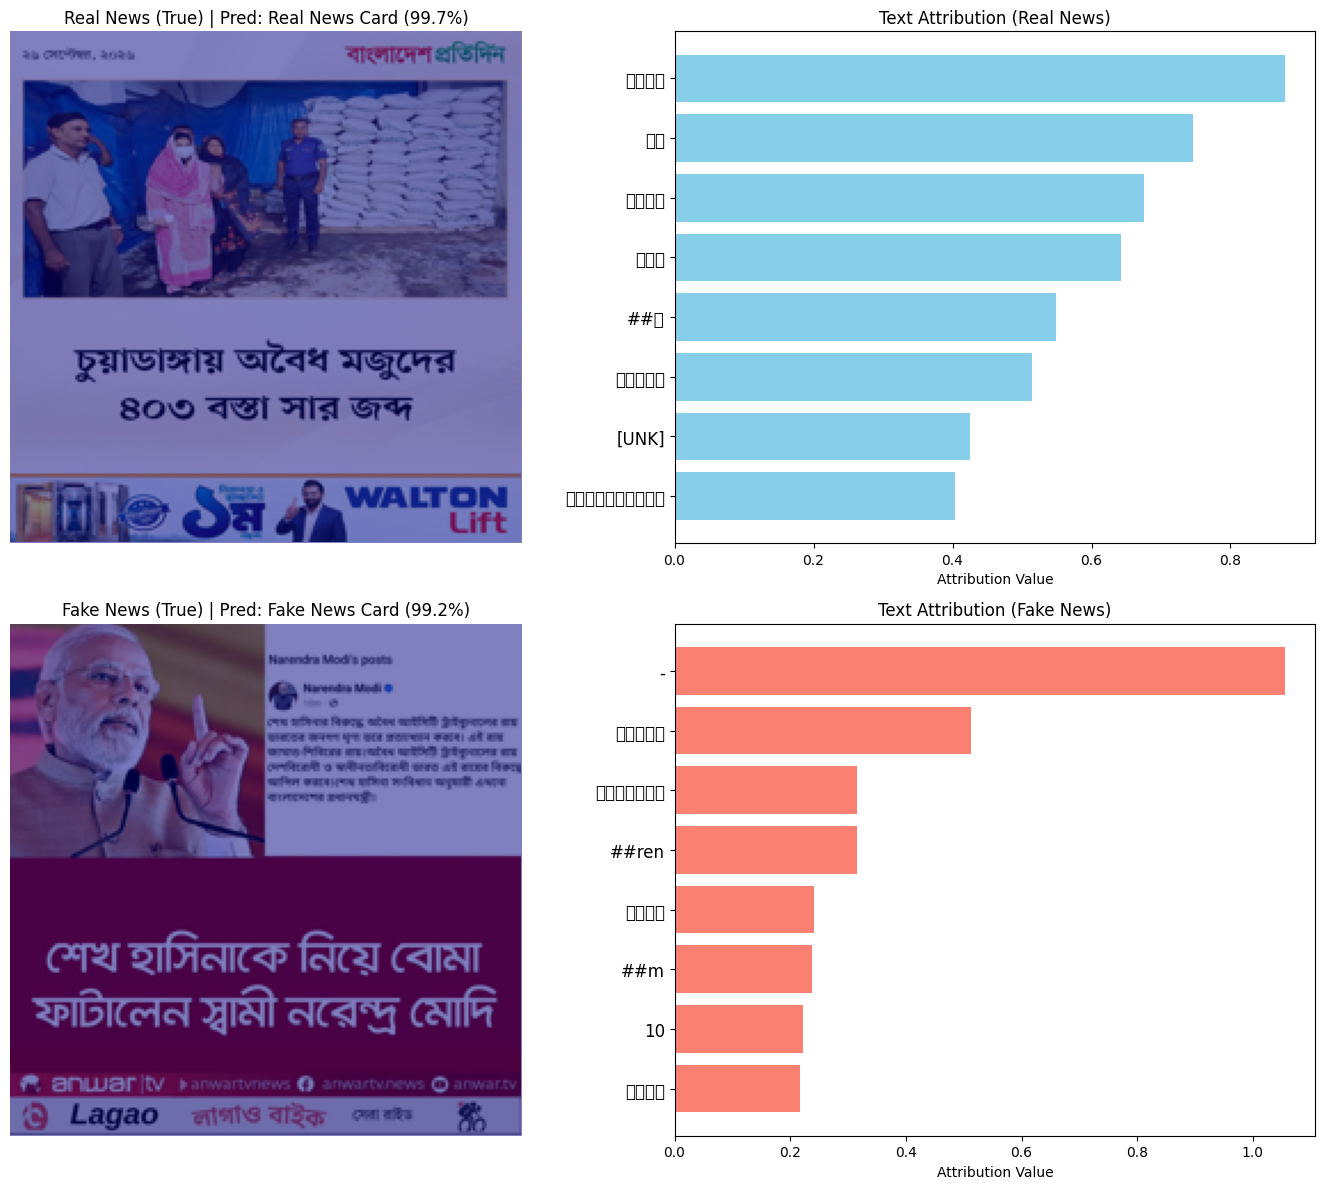

In [2]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import urllib.request
from tqdm import tqdm
from PIL import Image

import torch
from torch import nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel, SwinModel
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import random
import easyocr
from captum.attr import LayerGradCam, IntegratedGradients



# 1. Seed & Device Setup
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# 2. Paths Configuration
base_path = '/kaggle/input/datasets/mdmuradhosen999/bengali-photocard-1/Bengali Photocard Dataset'

csv_paths = {
    'train': f'{base_path}/Train.csv',      
    'test': f'{base_path}/Test.csv',        
    'validation': f'{base_path}/Validation.csv'    
}

processed_csv_paths = {
    'train': '/kaggle/working/Train_processed.csv',      
    'test': '/kaggle/working/Test_processed.csv',        
    'validation': '/kaggle/working/Validation_processed.csv'    
}

image_dirs = {
    'train': f'{base_path}/Train',          
    'test': f'{base_path}/Test',
    'validation': f'{base_path}/Validation'  
}

BATCH_SIZE = 8            
MAX_SEQ_LENGTH = 128    
EPOCHS = 35               
LEARNING_RATE = 5e-5  

# 3. OCR Text Preprocessing
def clean_ocr_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'[^\w\s\u0980-\u09FF।!?,.-]', ' ', text)
    return " ".join(text.split())

def preprocess_and_save_ocr(input_csv, image_dir, output_csv):
    if os.path.exists(output_csv):
        print(f"Found existing preprocessed CSV: {output_csv}")
        return

    print(f"\nProcessing OCR for CSV: {input_csv}")
    ocr_reader = easyocr.Reader(['bn', 'en'], gpu=torch.cuda.is_available())
    df = pd.read_csv(input_csv)
    ocr_texts = []

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Extracting OCR Text"):
        img_id = str(row['Image_id']).strip()
        img_path = None
        for ext in ['.jpg', '.png', '.jpeg', '.JPG', '.PNG']:
            possible_path = os.path.join(image_dir, img_id + ext)
            if os.path.exists(possible_path):
                img_path = possible_path
                break

        extracted_text = ""
        if img_path:
            try:
                results = ocr_reader.readtext(img_path, detail=0)
                if results:
                    raw_text = " ".join([str(res) for res in results]).strip()
                    extracted_text = clean_ocr_text(raw_text)
            except Exception:
                extracted_text = ""
        
        ocr_texts.append(extracted_text)

    df['ocr_text'] = ocr_texts
    df.to_csv(output_csv, index=False)
    print(f"Saved preprocessed dataset to: {output_csv}")

print("\nStarting Automated OCR Extraction...")
preprocess_and_save_ocr(csv_paths['train'], image_dirs['train'], processed_csv_paths['train'])
preprocess_and_save_ocr(csv_paths['validation'], image_dirs['validation'], processed_csv_paths['validation'])
preprocess_and_save_ocr(csv_paths['test'], image_dirs['test'], processed_csv_paths['test'])

# 4. Image Preprocessing & DataLoader Setup
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),  
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class MultiFusionDataset(Dataset):
    def __init__(self, processed_csv_file, original_csv_file, image_dir, transform=None):
        self.df = pd.read_csv(processed_csv_file)
        self.df.columns = self.df.columns.str.lower()
        
        orig_df = pd.read_csv(original_csv_file)
        orig_df.columns = orig_df.columns.str.lower()
        
        if 'finetuned' in orig_df.columns:
            if 'finetuned' not in self.df.columns:
                self.df = self.df.merge(orig_df[['image_id', 'finetuned']], on='image_id', how='left')
            else:
                self.df['finetuned'] = self.df['finetuned'].fillna(orig_df['finetuned'])
        
        self.image_dir = image_dir
        self.transform = transform

        image_files = os.listdir(image_dir) if os.path.exists(image_dir) else []
        self.image_names = {os.path.splitext(f)[0].strip(): os.path.join(image_dir, f) for f in image_files}
        self.df['image_path'] = self.df['image_id'].apply(lambda x: self.image_names.get(str(x).strip(), None))
        
        valid_count = self.df['image_path'].notna().sum()
        print(f"📄 Loaded CSV: {os.path.basename(processed_csv_file)} | 🖼️ Found Images: {valid_count} / {len(self.df)}")
        self.df = self.df.dropna(subset=['image_path']).reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'image_path']
        
        raw_description = str(self.df.loc[idx, 'finetuned']).strip() if 'finetuned' in self.df.columns and pd.notna(self.df.loc[idx, 'finetuned']) else ""
        ocr_text = str(self.df.loc[idx, 'ocr_text']).strip() if 'ocr_text' in self.df.columns and pd.notna(self.df.loc[idx, 'ocr_text']) else ""
        
        if ocr_text and raw_description:
            combined_text = raw_description if (ocr_text in raw_description or raw_description in ocr_text) else f"{ocr_text} {raw_description}"
        elif ocr_text:
            combined_text = ocr_text
        else:
            combined_text = raw_description

        label = int(self.df.loc[idx, 'label'])
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, combined_text, label, img_path

train_dataset = MultiFusionDataset(processed_csv_paths['train'], csv_paths['train'], image_dirs['train'], transform=transform)
val_dataset = MultiFusionDataset(processed_csv_paths['validation'], csv_paths['validation'], image_dirs['validation'], transform=test_transform)
test_dataset = MultiFusionDataset(processed_csv_paths['test'], csv_paths['test'], image_dirs['test'], transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 5. SWIN TRANSFORMER + BANGLABERT INTERMEDIATE FUSION ARCHITECTURE (Dropout Reduced)
TEXT_MODEL_NAME = "csebuetnlp/banglabert"  
SWIN_MODEL_NAME = "microsoft/swin-base-patch4-window7-224"

text_tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME)
text_encoder = AutoModel.from_pretrained(TEXT_MODEL_NAME)
swin_encoder = SwinModel.from_pretrained(SWIN_MODEL_NAME)

class CrossAttentionFusionBlock(nn.Module):
    def __init__(self, text_dim, img_dim, embed_dim=512, num_heads=8):
        super(CrossAttentionFusionBlock, self).__init__()
        self.proj_text = nn.Linear(text_dim, embed_dim)
        self.proj_img = nn.Linear(img_dim, embed_dim)
        
        self.cross_attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, batch_first=True)
        self.norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(0.2)

    def forward(self, text_feat, img_feat):
        t = self.proj_text(text_feat).unsqueeze(1)
        v = self.proj_img(img_feat).unsqueeze(1)
        
        attn_out, _ = self.cross_attn(query=t, key=v, value=v)
        fused = self.norm(t + self.dropout(attn_out)).squeeze(1)
        return fused

class SwinBertIntermediateFusionModel(nn.Module):
    def __init__(self, swin_model, text_model, num_classes=2, embed_dim=512):
        super(SwinBertIntermediateFusionModel, self).__init__()
        self.swin_model = swin_model
        self.text_model = text_model
        
        img_dim = self.swin_model.config.hidden_size      # 1024
        text_dim = self.text_model.config.hidden_size    # 768
        
        self.intermediate_fusion = CrossAttentionFusionBlock(text_dim=text_dim, img_dim=img_dim, embed_dim=embed_dim)
        
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 512), 
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),  # Dropout reduced from 0.5 to 0.3
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),  # Dropout reduced from 0.4 to 0.2
            nn.Linear(128, num_classes)
        )

    def forward(self, images, input_ids=None, attention_mask=None, inputs_embeds=None):
        swin_outputs = self.swin_model(pixel_values=images)
        img_features = swin_outputs.pooler_output  
        
        if inputs_embeds is not None:
            text_outputs = self.text_model(inputs_embeds=inputs_embeds, attention_mask=attention_mask)
        else:
            text_outputs = self.text_model(input_ids=input_ids, attention_mask=attention_mask)
            
        text_features = text_outputs.last_hidden_state[:, 0, :]
        fused_features = self.intermediate_fusion(text_features, img_features)
        
        logits = self.classifier(fused_features)
        return logits

model = SwinBertIntermediateFusionModel(swin_encoder, text_encoder).to(device)

# 6. Fine-tuning Layer Freezing Strategy (Unfreezed more layers)
for param in model.swin_model.parameters():
    param.requires_grad = False
for name, param in model.swin_model.named_parameters():
    if "encoder.layers.2" in name or "encoder.layers.3" in name or "layernorm" in name:
        param.requires_grad = True

for param in model.text_model.parameters():
    param.requires_grad = False
for name, param in model.text_model.named_parameters():
    if "encoder.layer.9" in name or "encoder.layer.10" in name or "encoder.layer.11" in name or "pooler" in name:
        param.requires_grad = True

for param in model.intermediate_fusion.parameters():
    param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

# 7. Optimizer, Scheduler & Class-Weighted Loss Setup
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE, weight_decay=1e-5)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# Added class weights to prevent bias towards 'Real' class [Real, Fake]
class_weights = torch.tensor([1.0, 2.5]).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

'''
# ---------------------------------------------------------
# Training Loop
# ---------------------------------------------------------
patience = 6
patience_counter = 0
best_val_loss = float('inf')

print("\nStarting Swin Transformer + Text Transformer Intermediate Fusion Training...")

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for images, texts, labels, _ in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False):
        images = images.to(device)
        labels = labels.to(device)
        
        inputs = text_tokenizer(list(texts), padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)
        
        optimizer.zero_grad()
        logits = model(images, input_ids=input_ids, attention_mask=attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = logits.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    
    # Validation Loop
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    
    with torch.no_grad():
        for images, texts, labels, _ in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            inputs = text_tokenizer(list(texts), padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
            input_ids = inputs['input_ids'].to(device)
            attention_mask = inputs['attention_mask'].to(device)
            
            logits = model(images, input_ids=input_ids, attention_mask=attention_mask)
            val_loss_batch = criterion(logits, labels)
            val_running_loss += val_loss_batch.item()
            
            _, predicted = logits.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            
    val_loss = val_running_loss / len(val_loader)
    val_acc = val_correct / val_total
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f}")
    
    scheduler.step(val_loss)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), '/kaggle/working/best_swin_bert_intermediatefusion.pth')
        print(f"   ---> Best Model Saved! (Val Loss: {val_loss:.4f})")
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("\nEarly stopping triggered!")
            break

'''

# 8. Testing & Evaluation Phase
print("\nEvaluation Phase Starting...")
model_path = '/kaggle/working/best_swin_bert_intermediatefusion.pth'

if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    print("✅ Best saved Intermediate Fusion Model Loaded Successfully!")

model.eval()
predicted_labels, true_labels = [], []

with torch.no_grad():
    for images, texts, labels, _ in tqdm(test_loader, desc='Testing'):
        images = images.to(device)
        inputs = text_tokenizer(list(texts), padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
        
        logits = model(images, input_ids=inputs['input_ids'].to(device), attention_mask=inputs['attention_mask'].to(device))
        _, predicted = logits.max(1)
        
        predicted_labels.extend(predicted.cpu().numpy())
        true_labels.extend(labels.numpy())

# 9. Performance Metrics Output
predicted_labels = np.array(predicted_labels)
true_labels = np.array(true_labels)

accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(true_labels, predicted_labels, average='weighted', zero_division=0)
recall = recall_score(true_labels, predicted_labels, average='weighted', zero_division=0)
f1 = f1_score(true_labels, predicted_labels, average='weighted', zero_division=0)

print(f"\nTEST RESULT")
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall   : {recall:.4f}")
print(f"Test F1 Score : {f1:.4f}")

# Confusion Matrix
conf_matrix = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, cmap='Blues', fmt='d', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Intermediate Fusion Model(Swin+BanglaBert) - Confusion Matrix')
plt.show()

# ---------------------------------------------------------
# 10. EXPLAINABLE AI (XAI) MODULE WITH BENGALI FONT SUPPORT
# ---------------------------------------------------------
font_path = '/tmp/Kalpurush.ttf'
if not os.path.exists(font_path):
    try:
        url = "https://github.com/bangla/font-repository/raw/master/Kalpurush.ttf"
        urllib.request.urlretrieve(url, font_path)
    except Exception:
        pass

if os.path.exists(font_path):
    bengali_font = fm.FontProperties(fname=font_path)
else:
    bengali_font = None

def generate_swin_intermediate_xai(model, image_path, text_string, target_class=None):
    model.eval()
    
    raw_img = Image.open(image_path).convert('RGB')
    transformed_img = test_transform(raw_img).unsqueeze(0).to(device)
    
    inputs = text_tokenizer(text_string, padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)
    
    with torch.no_grad():
        logits = model(transformed_img, input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1).item()
        confidence = probs[0][pred_class].item() * 100
        
    if target_class is None:
        target_class = pred_class

    
    class_names = {0: 'Fake News Card', 1: 'Real News Card'}
    
    # --- A. SWIN GRAD-CAM ---
    def forward_image_swin(img):
        return model(img, input_ids=input_ids, attention_mask=attention_mask)

    target_layer = model.swin_model.encoder.layers[-1].blocks[-1].layernorm_before
    layer_gc = LayerGradCam(forward_func=forward_image_swin, layer=target_layer)
    attr_gradcam = layer_gc.attribute(transformed_img, target=target_class)
    
    heatmap_tokens = attr_gradcam.squeeze(0) 
    heatmap_2d = heatmap_tokens.mean(dim=-1).detach().cpu().numpy() 
    grid_size = int(np.sqrt(heatmap_2d.shape[0])) 
    heatmap_grid = heatmap_2d.reshape(grid_size, grid_size)
    
    heatmap_grid = np.maximum(heatmap_grid, 0)
    if np.max(heatmap_grid) > 0:
        heatmap_grid /= np.max(heatmap_grid)
        
    # --- B. TEXT INTEGRATED GRADIENTS ---
    embedding_layer = model.text_model.get_input_embeddings()
    with torch.no_grad():
        embeddings = embedding_layer(input_ids)
    
    def forward_text(embeds):
        bsz = embeds.shape[0]
        expanded_img = transformed_img.expand(bsz, -1, -1, -1)
        expanded_mask = attention_mask.expand(bsz, -1)
        return model(expanded_img, inputs_embeds=embeds, attention_mask=expanded_mask)

    ig = IntegratedGradients(forward_text)
    
    attributions = ig.attribute(
        inputs=embeddings,
        target=target_class,
        n_steps=10,
        internal_batch_size=1
    )
    
    token_importance = attributions.sum(dim=-1).squeeze(0).cpu().detach().numpy()
    tokens = text_tokenizer.convert_ids_to_tokens(input_ids[0])
    
    # --- C. PLOTTING ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    axes[0].imshow(raw_img.resize((224, 224)))
    axes[0].imshow(heatmap_grid, cmap='jet', alpha=0.5, extent=(0, 224, 224, 0))
    axes[0].set_title(f"Swin-Intermediate Grad-CAM\nPred: {class_names[pred_class]} ({confidence:.1f}%)")
    axes[0].axis('off')
    
    valid_tokens, valid_scores = [], []
    for tok, score in zip(tokens, token_importance):
        if tok not in ['[PAD]', '[CLS]', '[SEP]']:
            valid_tokens.append(tok)
            valid_scores.append(abs(score))
            
    if len(valid_tokens) > 0:
        top_indices = np.argsort(valid_scores)[-10:]
        top_tokens = [valid_tokens[i] for i in top_indices]
        top_scores = [valid_scores[i] for i in top_indices]
        
        y_pos = np.arange(len(top_tokens))
        axes[1].barh(y_pos, top_scores, color='skyblue')
        axes[1].set_yticks(y_pos)
        
        if bengali_font:
            axes[1].set_yticklabels(top_tokens, fontproperties=bengali_font)
        else:
            axes[1].set_yticklabels(top_tokens)
    else:
        axes[1].text(0.5, 0.5, "No Text Tokens", ha='center', va='center')
        
    axes[1].set_title("Text Explanation (Top Tokens)")
    axes[1].set_xlabel("Attribution Value")
    
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 11. RUN XAI ON SAMPLES
# ---------------------------------------------------------
# ---------------------------------------------------------
# 11. RUN XAI ON SAMPLES (3 ti Real ebong 3 ti Fake sample soho)
# ---------------------------------------------------------
'''
print("\nRunning Swin + BanglaBERT Intermediate Fusion XAI outputs for multiple Real and Fake samples...")

real_count = 0
fake_count = 0
target_real = 3
target_fake = 3

for i in range(len(test_dataset)):
    _, text, label, img_p = test_dataset[i]
    
    # Label 1 mane Real news ebong Label 0 mane Fake news
    if label == 1 and real_count < target_real:
        print(f"\n--- Evaluating Real Sample {real_count+1} (Index {i}) ---")
        generate_swin_intermediate_xai(model, img_p, text)
        real_count += 1
        
    elif label == 0 and fake_count < target_fake:
        print(f"\n--- Evaluating Fake Sample {fake_count+1} (Index {i}) ---")
        generate_swin_intermediate_xai(model, img_p, text)
        fake_count += 1
        
    # Jodi duita category thekei 3 ti kore sample paoa hoye jay, tahole loop bondho kore dibo
    if real_count >= target_real and fake_count >= target_fake:
        break

'''

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ১. বাংলা কালপুরুষ ফন্ট সিস্টেমে যুক্ত ও সেট করা
font_path = '/tmp/Kalpurush.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    bengali_font_prop = fm.FontProperties(fname=font_path)
    plt.rc('font', family='Kalpurush')
else:
    bengali_font_prop = None

# ২. আপডেট করা কম্প্যারিজন ফাংশন
def compare_real_and_fake_xai(model, test_dataset):
    model.eval()
    
    # ১টি Real (label 1) এবং ১টি Fake (label 0) স্যাম্পল নির্বাচন
    real_sample = None
    fake_sample = None
    
    for _, text, label, img_p in test_dataset:
        if label == 1 and real_sample is None:
            real_sample = (img_p, text, label)
        elif label == 0 and fake_sample is None:
            fake_sample = (img_p, text, label)
        if real_sample and fake_sample:
            break
            
    samples = [('Real News', real_sample), ('Fake News', fake_sample)]
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    
    for idx, (title_prefix, sample) in enumerate(samples):
        if sample is None:
            continue
        img_path, text_string, label = sample
        
        raw_img = Image.open(img_path).convert('RGB')
        transformed_img = test_transform(raw_img).unsqueeze(0).to(device)
        
        inputs = text_tokenizer(text_string, padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)
        
        with torch.no_grad():
            logits = model(transformed_img, input_ids=input_ids, attention_mask=attention_mask)
            probs = torch.softmax(logits, dim=1)
            pred_class = torch.argmax(probs, dim=1).item()
            confidence = probs[0][pred_class].item() * 100
            
        class_names = {0: 'Fake News Card', 1: 'Real News Card'}
        
        # A. Grad-CAM (Image)
        def forward_image_swin(img):
            return model(img, input_ids=input_ids, attention_mask=attention_mask)

        target_layer = model.swin_model.encoder.layers[-1].blocks[-1].layernorm_before
        layer_gc = LayerGradCam(forward_func=forward_image_swin, layer=target_layer)
        attr_gradcam = layer_gc.attribute(transformed_img, target=pred_class)
        
        heatmap_tokens = attr_gradcam.squeeze(0)
        heatmap_2d = heatmap_tokens.mean(dim=-1).detach().cpu().numpy()
        grid_size = int(np.sqrt(heatmap_2d.shape[0]))
        heatmap_grid = heatmap_2d.reshape(grid_size, grid_size)
        heatmap_grid = np.maximum(heatmap_grid, 0)
        if np.max(heatmap_grid) > 0:
            heatmap_grid /= np.max(heatmap_grid)
            
        # B. Text Integrated Gradients
        embedding_layer = model.text_model.get_input_embeddings()
        with torch.no_grad():
            embeddings = embedding_layer(input_ids)
        
        def forward_text(embeds):
            bsz = embeds.shape[0]
            expanded_img = transformed_img.expand(bsz, -1, -1, -1)
            expanded_mask = attention_mask.expand(bsz, -1)
            return model(expanded_img, inputs_embeds=embeds, attention_mask=expanded_mask)

        ig = IntegratedGradients(forward_text)
        attributions = ig.attribute(inputs=embeddings, target=pred_class, n_steps=10, internal_batch_size=1)
        token_importance = attributions.sum(dim=-1).squeeze(0).cpu().detach().numpy()
        tokens = text_tokenizer.convert_ids_to_tokens(input_ids[0])
        
        # Plot Image (Left Side)
        axes[idx, 0].imshow(raw_img.resize((224, 224)))
        axes[idx, 0].imshow(heatmap_grid, cmap='jet', alpha=0.5, extent=(0, 224, 224, 0))
        axes[idx, 0].set_title(f"{title_prefix} (True) | Pred: {class_names[pred_class]} ({confidence:.1f}%)")
        axes[idx, 0].axis('off')
        
        # Plot Text Tokens (Right Side)
        valid_tokens, valid_scores = [], []
        for tok, score in zip(tokens, token_importance):
            if tok not in ['[PAD]', '[CLS]', '[SEP]']:
                valid_tokens.append(tok)
                valid_scores.append(abs(score))
                
        if len(valid_tokens) > 0:
            top_indices = np.argsort(valid_scores)[-8:]
            top_tokens = [valid_tokens[i] for i in top_indices]
            top_scores = [valid_scores[i] for i in top_indices]
            
            y_pos = np.arange(len(top_tokens))
            axes[idx, 1].barh(y_pos, top_scores, color='salmon' if idx==1 else 'skyblue')
            axes[idx, 1].set_yticks(y_pos)
            
            # বাংলা ফন্ট ফিক্সসহ Tick Labels সেট করা
            if bengali_font_prop:
                axes[idx, 1].set_yticklabels(top_tokens, fontproperties=bengali_font_prop, fontsize=12)
            else:
                axes[idx, 1].set_yticklabels(top_tokens, fontsize=12)
        else:
            axes[idx, 1].text(0.5, 0.5, "No Text Tokens", ha='center', va='center')
            
        axes[idx, 1].set_title(f"Text Attribution ({title_prefix})")
        axes[idx, 1].set_xlabel("Attribution Value")
        
    plt.tight_layout()
    plt.show()

# ফাংশনটি কল করার জন্য:
compare_real_and_fake_xai(model, test_dataset)